In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("graduados_2020_2025.csv")
print(df.shape)
print(df.columns.tolist())
print(df["sexo"].value_counts(dropna=False))

(273485, 15)
['institucion', 'sector', 'caracter_institucion', 'departamento', 'programa', 'nivel_academico', 'nivel_formacion', 'area_conocimiento', 'sexo', 'anio', 'semestre', 'graduados', 'departamento_normalizado', 'nivel_formacion_normalizado', 'sector_normalizado']
sexo
MASCULINO     137583
FEMENINO      135890
NO BINARIO        12
Name: count, dtype: int64


In [2]:
MIN_GRAD = 15  # umbral mínimo de graduados por programa-año (decisión del documento)

# Usar la versión normalizada de la columna si existe
def col(nombre):
    return f"{nombre}_normalizado" if f"{nombre}_normalizado" in df.columns else nombre

llaves = ["anio", "institucion", col("sector"), "caracter_institucion",
          col("departamento"), "programa", col("nivel_formacion"), "area_conocimiento"]

sexo = df["sexo"].astype(str).str.upper().str.strip()
df["mujeres"] = np.where(sexo.str.startswith(("MUJER", "FEMEN")), df["graduados"], 0)
df["hombres"] = np.where(sexo.str.startswith(("HOMBRE", "MASCU")), df["graduados"], 0)
df["no_binario"] = np.where(sexo.str.startswith("NO BIN"), df["graduados"], 0)

# Base completa: una fila por programa-año
prog_todo = df.groupby(llaves, dropna=False)[["mujeres", "hombres", "no_binario"]].sum().reset_index()
prog_todo["total"] = prog_todo[["mujeres", "hombres", "no_binario"]].sum(axis=1)
prog_todo = prog_todo[prog_todo["total"] > 0].copy()
prog_todo["prop_mujeres"] = prog_todo["mujeres"] / prog_todo["total"]

# Base de trabajo: solo programas-año con 15 o más graduados
prog = prog_todo[prog_todo["total"] >= MIN_GRAD].copy()

print("Registros programa-año (todos):", len(prog_todo))
print("Registros con 15+ graduados:", len(prog))
print("Instituciones:", prog["institucion"].nunique())
print("Programas:", prog[["institucion", "programa", col("nivel_formacion"), col("departamento")]].drop_duplicates().shape[0])
print(f"% mujeres ponderado: {prog['mujeres'].sum() / prog['total'].sum():.1%}")
print(f"% de graduados que se conservan: {prog['total'].sum() / prog_todo['total'].sum():.1%}")

Registros programa-año (todos): 82819
Registros con 15+ graduados: 41399
Instituciones: 318
Programas: 11923
% mujeres ponderado: 56.6%
% de graduados que se conservan: 92.9%


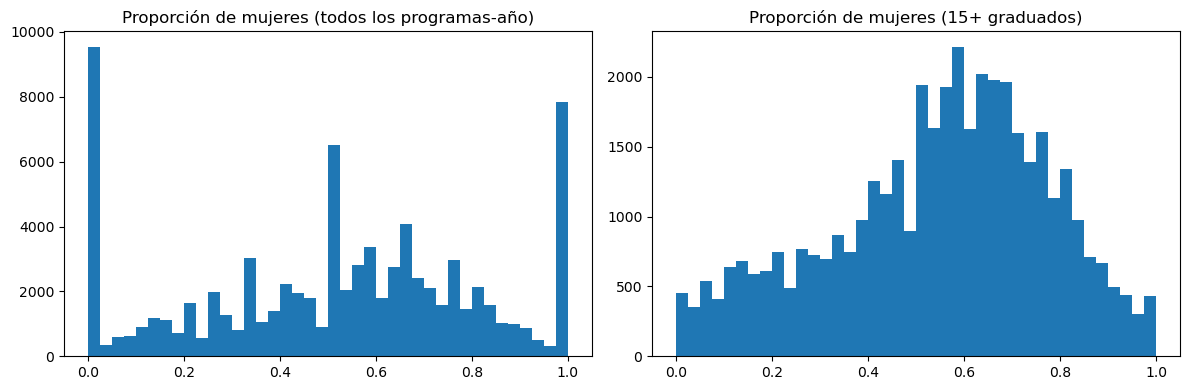

Umbral 10: excluye 40.0% de los registros y conserva 96.0% de los graduados
Umbral 15: excluye 50.0% de los registros y conserva 92.9% de los graduados
Umbral 30: excluye 67.8% de los registros y conserva 83.0% de los graduados

Base completa - con 0% mujeres: 11.4%, con 100%: 9.3%
Base 15+ - con 0% mujeres: 359, con 100%: 309
Base 15+ - media: 54.5%, mediana: 57.8%
Base 15+ - percentiles 5 y 95: 11.1% y 88.2%


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(prog_todo["prop_mujeres"], bins=40)
ax[0].set_title("Proporción de mujeres (todos los programas-año)")
ax[1].hist(prog["prop_mujeres"], bins=40)
ax[1].set_title(f"Proporción de mujeres ({MIN_GRAD}+ graduados)")
plt.tight_layout()
plt.show()

for corte in [10, 15, 30]:
    excl = prog_todo["total"] < corte
    conserva = prog_todo.loc[~excl, "total"].sum() / prog_todo["total"].sum()
    print(f"Umbral {corte}: excluye {excl.mean():.1%} de los registros y conserva {conserva:.1%} de los graduados")

print(f"\nBase completa - con 0% mujeres: {(prog_todo['prop_mujeres'] == 0).mean():.1%}, con 100%: {(prog_todo['prop_mujeres'] == 1).mean():.1%}")
print(f"Base 15+ - con 0% mujeres: {(prog['prop_mujeres'] == 0).sum()}, con 100%: {(prog['prop_mujeres'] == 1).sum()}")
print(f"Base 15+ - media: {prog['prop_mujeres'].mean():.1%}, mediana: {prog['prop_mujeres'].median():.1%}")
print(f"Base 15+ - percentiles 5 y 95: {prog['prop_mujeres'].quantile(.05):.1%} y {prog['prop_mujeres'].quantile(.95):.1%}")

anio                           0.001
caracter_institucion           0.006
departamento_normalizado       0.019
nivel_formacion_normalizado    0.019
sector_normalizado             0.023
institucion                    0.197
area_conocimiento              0.298
dtype: float64


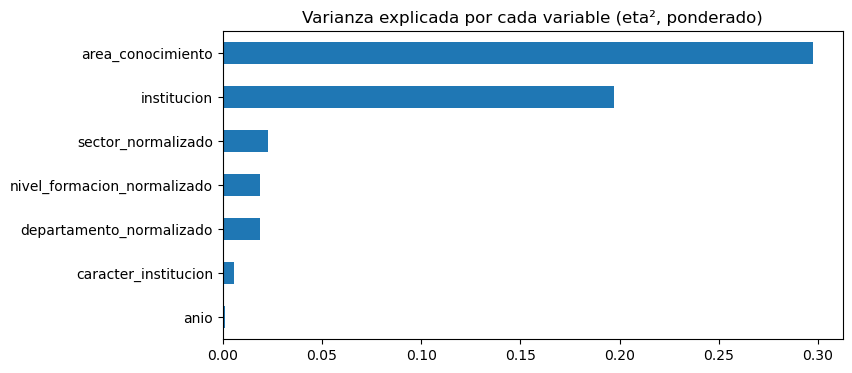

In [4]:
def eta2(data, var, y="prop_mujeres", w="total"):
    d = data.dropna(subset=[var]).copy()
    d["yw"] = d[y] * d[w]
    media = d["yw"].sum() / d[w].sum()
    g = d.groupby(var).agg(yw=("yw", "sum"), w=(w, "sum"))
    g["m"] = g["yw"] / g["w"]
    ss_entre = (g["w"] * (g["m"] - media) ** 2).sum()
    ss_total = (d[w] * (d[y] - media) ** 2).sum()
    return ss_entre / ss_total

variables = ["area_conocimiento", col("nivel_formacion"), col("sector"),
             "caracter_institucion", col("departamento"), "anio", "institucion"]

res = pd.Series({v: eta2(prog, v) for v in variables}).sort_values()
print(res.round(3))

res.plot(kind="barh", figsize=(8, 4), title="Varianza explicada por cada variable (eta², ponderado)")
plt.show()

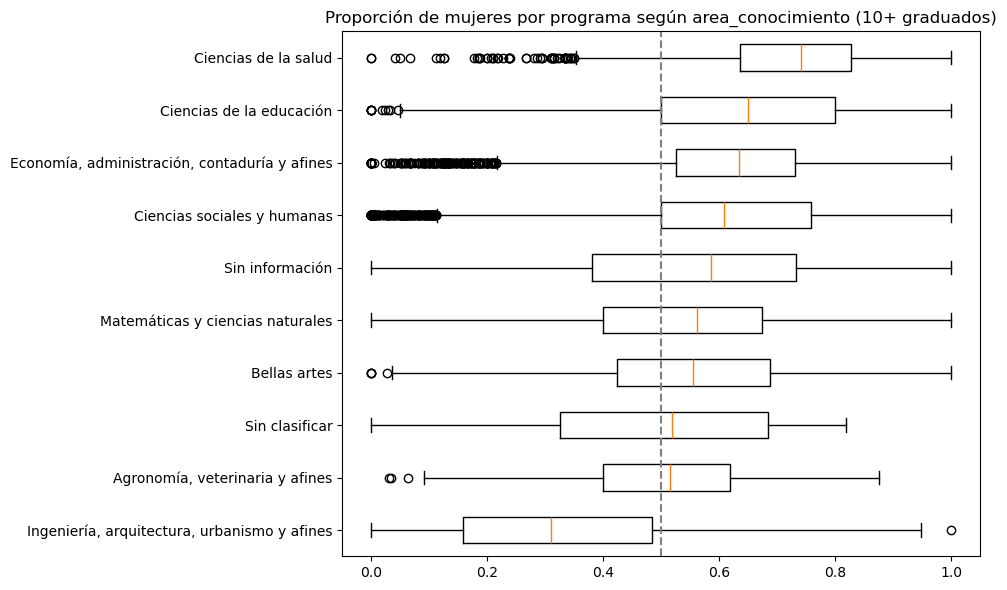

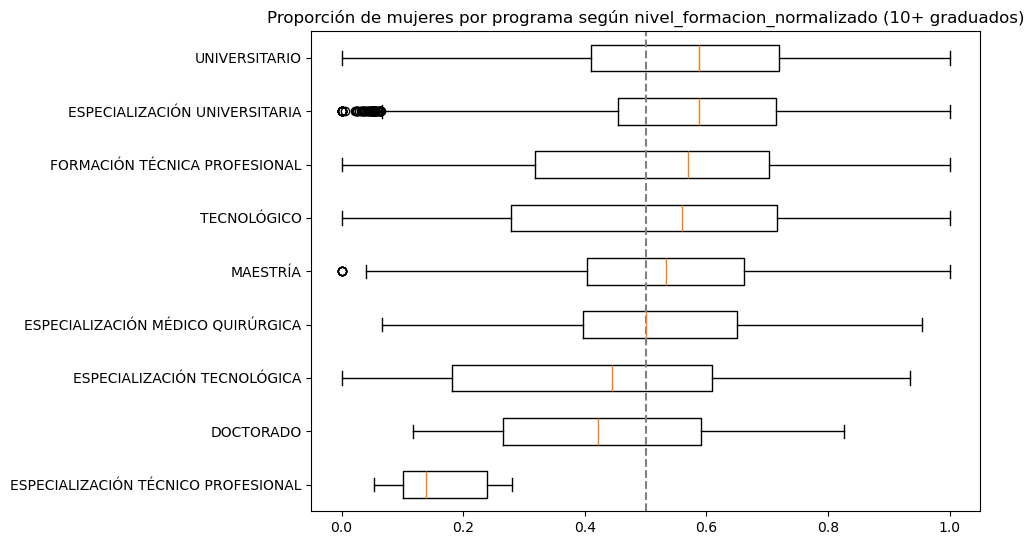

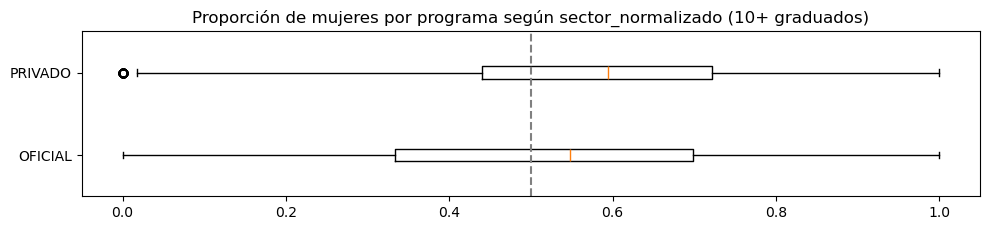

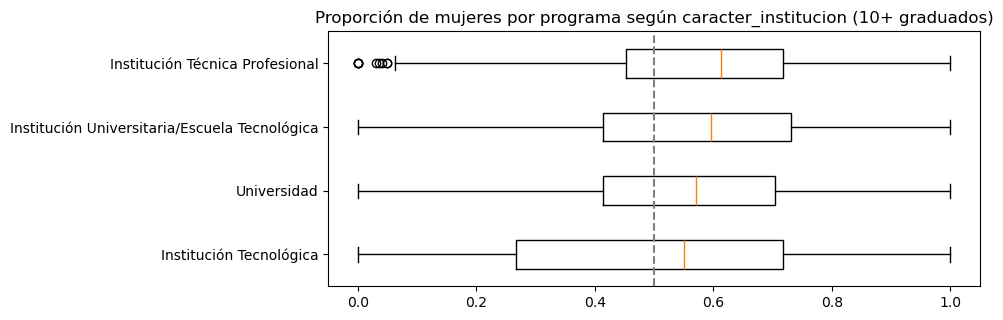

In [5]:
base = prog[prog["total"] >= 10]

for var in ["area_conocimiento", col("nivel_formacion"), col("sector"), "caracter_institucion"]:
    orden = base.groupby(var)["prop_mujeres"].median().sort_values().index
    datos = [base.loc[base[var] == k, "prop_mujeres"] for k in orden]
    plt.figure(figsize=(10, 0.45 * len(orden) + 1.5))
    plt.boxplot(datos, vert=False)
    plt.yticks(range(1, len(orden) + 1), orden)
    plt.axvline(0.5, linestyle="--", color="grey")
    plt.title(f"Proporción de mujeres por programa según {var} (10+ graduados)")
    plt.tight_layout()
    plt.show()

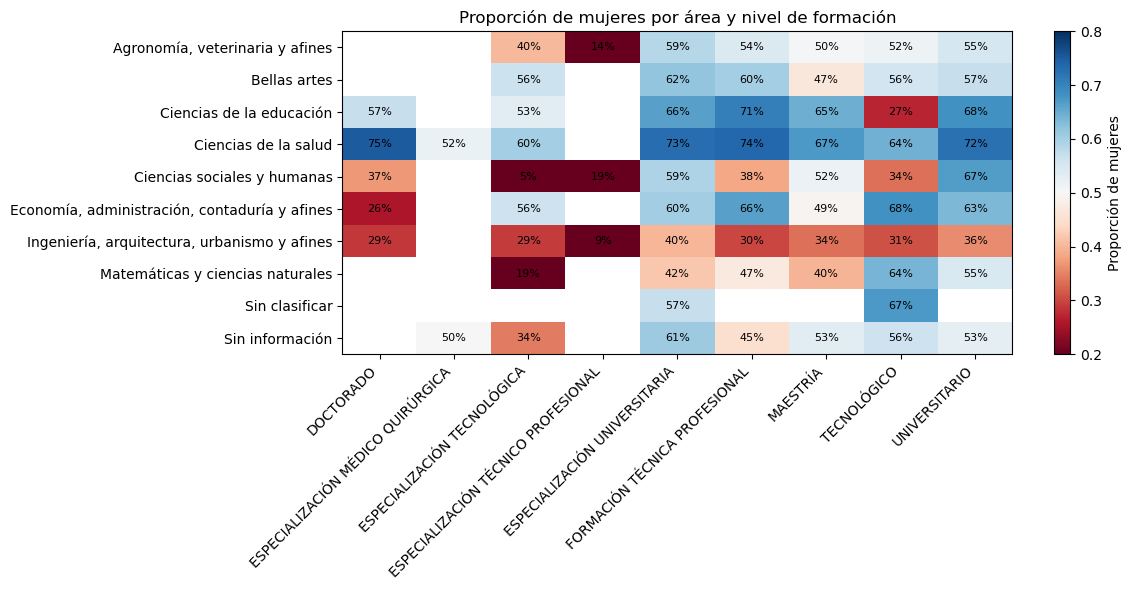

In [6]:
t = prog.groupby(["area_conocimiento", col("nivel_formacion")])[["mujeres", "total"]].sum()
tabla = (t["mujeres"] / t["total"]).unstack()

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(tabla, cmap="RdBu", vmin=0.2, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(tabla.columns)), tabla.columns, rotation=45, ha="right")
ax.set_yticks(range(len(tabla.index)), tabla.index)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Proporción de mujeres")
plt.title("Proporción de mujeres por área y nivel de formación")
plt.tight_layout()
plt.show()

Correlación año t vs año t-1: 0.842
Registros con año anterior disponible: 31003 de 41399
anio
1    3695
2    2144
3    1345
4    1176
5    1435
6    2917
Name: count, dtype: int64


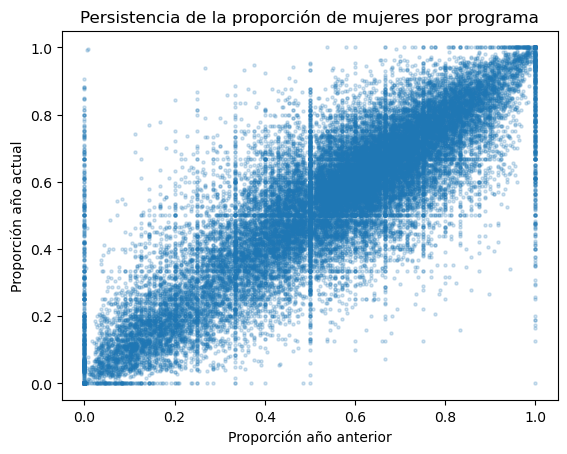

Guardado programas_anio.csv: (41399, 14)


In [8]:
id_prog = [c for c in llaves if c != "anio"]

# El rezago se calcula sobre la base completa, para no saltarse años
t = prog_todo.sort_values(id_prog + ["anio"]).copy()
t["prop_anio_anterior"] = t.groupby(id_prog, dropna=False)["prop_mujeres"].shift(1)
t["anio_anterior"] = t.groupby(id_prog, dropna=False)["anio"].shift(1)
# Solo vale si el registro anterior es del año inmediatamente anterior
t.loc[t["anio"] - t["anio_anterior"] != 1, "prop_anio_anterior"] = np.nan

# Base final para el modelo: 15+ graduados
prog = t[t["total"] >= MIN_GRAD].drop(columns="anio_anterior").copy()

p = prog.dropna(subset=["prop_anio_anterior"])
print(f"Correlación año t vs año t-1: {p['prop_mujeres'].corr(p['prop_anio_anterior']):.3f}")
print("Registros con año anterior disponible:", len(p), "de", len(prog))

anios_por_prog = prog.groupby(id_prog, dropna=False)["anio"].nunique()
print(anios_por_prog.value_counts().sort_index())

plt.scatter(p["prop_anio_anterior"], p["prop_mujeres"], s=5, alpha=0.2)
plt.xlabel("Proporción año anterior")
plt.ylabel("Proporción año actual")
plt.title("Persistencia de la proporción de mujeres por programa")
plt.show()

prog.to_csv("programas_anio.csv", index=False, encoding="utf-8-sig")
print("Guardado programas_anio.csv:", prog.shape)

## Conclusiones de la exploración

**1. Unidad de análisis y filtro.** La base se agregó a 82.819 registros programa-año. Se trabaja con los 41.399 que tienen 15 o más graduados: se excluye el 50,0 % de los registros, pero se conserva el 92,9 % de los graduados (318 instituciones). Los 12 graduados de la categoría "No binario" se mantienen en el total del programa.

**2. Variable objetivo.** La proporción de mujeres en la base de trabajo tiene media de 54,5 %, mediana de 57,8 % y un valor ponderado por graduados de 56,6 %. Los percentiles 5 y 95 son 11,1 % y 88,2 %. Solo 359 registros tienen 0 % de mujeres y 309 tienen 100 %. Sin el filtro, esos extremos eran el 11,4 % y el 9,3 % de la base, casi todos programas muy pequeños. Con un umbral de 10 se conserva el 96,0 % de los graduados (excluye el 40,0 % de los registros) y con 30 el 83,0 % (excluye el 67,8 %), por lo que 15 es un equilibrio razonable.

**3. Qué variables se asocian con la proporción (eta² ponderado).** El área de conocimiento es la más informativa (29,8 %), seguida de la institución (19,7 %, inflada por su alto número de categorías). Sector (2,3 %), nivel de formación (1,9 %), departamento (1,9 %) y carácter de la institución (0,6 %) aportan poco por sí solos, y el año prácticamente nada (0,1 %).

**4. Diferencias por grupo.** Ingeniería, arquitectura y afines tiene 34,4 % de mujeres y Ciencias de la salud 71,3 %. Dentro de cada área hay mucha dispersión: en Ingeniería la mediana de los programas es 31 % (la mitad central va de 16 % a 48 %) y en Salud es 74 % (de 64 % a 83 %). Las instituciones privadas tienen 59,5 % de mujeres y las oficiales 52,7 %. Entre los departamentos con al menos 2.000 graduados, Cundinamarca tiene la menor proporción (44,8 %) y Arauca (66,1 %), La Guajira (65,0 %) y Chocó (63,6 %) las mayores.

**5. Evolución en el tiempo.** La proporción es estable: 56,5 % en 2020, 57,4 % en 2022 y 55,6 % en 2025, con un descenso leve desde 2022.

**6. Interacción entre área y nivel.** El nivel de formación no se comporta igual en todas las áreas. En Economía y administración la proporción baja de 63 % en el nivel universitario a 49 % en maestría y 26 % en doctorado, y en Ciencias sociales de 67 % a 52 % y 37 %. En Ingeniería se mantiene entre 29 % y 36 % en todos los niveles. En Educación, el nivel tecnológico (27 %) es un caso atípico. El doctorado tiene pocos graduados, por lo que esas cifras se interpretan con cautela. Como el efecto de una variable depende de la otra, se justifica probar modelos que capturen interacciones (árboles, Random Forest o Gradient Boosting).

**7. Persistencia y riesgo de fuga de información.** La proporción de un programa en un año se correlaciona fuertemente con la del año anterior (r = 0,84, sobre 31.003 registros con año previo disponible). El panel es desbalanceado: 2.917 series aparecen en los seis años y 3.695 en un solo año. Esto implica dos cosas: el modelo debe validarse con partición temporal (entrenamiento 2020-2023, evaluación 2024-2025) y no puede depender solo de la proporción del año anterior, porque un programa nuevo no tiene historial.

**Implicaciones para el modelo.** Variable objetivo: proporción de mujeres por programa-año, ponderada por graduados y con 15 o más graduados. Predictores principales: área, nivel de formación, institución, sector y departamento, con la interacción área x nivel. La proporción del año anterior se evaluará como variable adicional, no como única. Los resultados describen asociaciones y no implican causalidad.